In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [10]:
def compute_cumulative_outcome_fractions(df, masses, N):
    """
    df      : DataFrame with columns ['mass', 'time', 'particle_id', 'result']
              where result is 'Ejected' or 'Captured', and each row represents
              the time at which that particle's outcome occurred
    masses  : list/array of unique mass values, in the same order as N
    N       : list/array of total particle counts, one per mass in `masses`

    Returns
    -------
    ejection_df, capture_df : DataFrames indexed by mass, columns = sorted
                               unique time values, entries = CUMULATIVE
                               fraction of N with that result by that time
                               (i.e. fraction ejected/captured at or before
                               each time, monotonically non-decreasing
                               across each row)
    """
    if len(masses) != len(N):
        raise ValueError("masses and N must be the same length")

    mass_to_N = dict(zip(masses, N))

    times = np.sort(df["time"].unique())

    ejection_df = pd.DataFrame(index=masses, columns=times, dtype=float)
    capture_df = pd.DataFrame(index=masses, columns=times, dtype=float)

    for mass in masses:
        mass_df = df[df["mass"] == mass]
        denom = mass_to_N[mass]

        counts = (
            mass_df.groupby(["time", "result"])
            .size()
            .unstack(fill_value=0)
        )

        # reindex to the full sorted time axis, filling any missing times
        # with 0 new outcomes at that time, then cumsum across time
        ejected_counts = counts.get("Ejected", pd.Series(0, index=counts.index))
        captured_counts = counts.get("Captured", pd.Series(0, index=counts.index))

        ejected_counts = ejected_counts.reindex(times, fill_value=0)
        captured_counts = captured_counts.reindex(times, fill_value=0)

        ejection_df.loc[mass] = (ejected_counts.cumsum() / denom).values
        capture_df.loc[mass] = (captured_counts.cumsum() / denom).values

    return ejection_df, capture_df

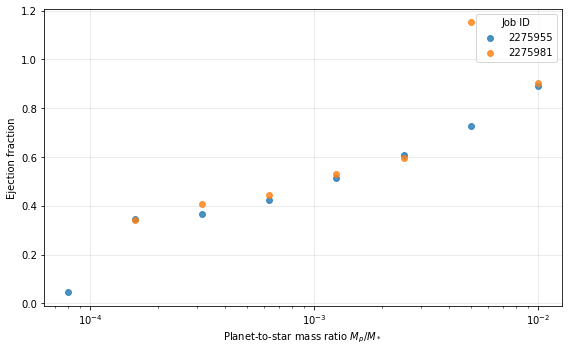

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

files = [
    Path("/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2275955_ejection_results.txt"),
    Path("/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2275981_ejection_results.txt"),
]

# Number of particles initialized at each planetary mass
N_particles = 500  # Change to your actual value

fig, ax = plt.subplots(figsize=(8, 5))

for file in files:
    df = pd.read_csv(
        file,
        header=None,
        names=["mass", "time", "status", "particle_id"]
    )

    df["status"] = df["status"].str.strip().str.lower()

    # Count each ejected particle only once per mass
    ejected = df[df["status"] == "ejected"].drop_duplicates(
        subset=["mass", "particle_id"]
    )

    counts = ejected.groupby("mass").size()

    # Include masses with zero ejections
    masses = sorted(df["mass"].unique())
    fractions = counts.reindex(masses, fill_value=0) / N_particles

    ax.scatter(
        masses,
        fractions,
        s=35,
        alpha=0.8,
        label=file.stem.split("_")[0]
    )

ax.set_xscale("log")
ax.set_xlabel(r"Planet-to-star mass ratio $M_p/M_*$")
ax.set_ylabel("Ejection fraction")
ax.legend(title="Job ID")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [19]:
df=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2275955_ejection_results.txt', header=None)

In [20]:
df.columns=['mass','time','result','particle_id']

In [21]:
df.mass.unique()

array([1.00000000e-02, 5.01187234e-03, 2.51188643e-03, 1.25892541e-03,
       1.58489319e-04, 7.94328235e-05, 6.30957344e-04, 3.16227766e-04])

In [22]:
df.tail()

,mass,time,result,particle_id
1992,0.000079,2.460902e+06,Ejected,718
1993,0.000079,2.522900e+06,Ejected,31
1994,0.000079,2.523900e+06,Ejected,136
1995,0.000079,2.541899e+06,Ejected,563
1996,0.000079,2.571898e+06,Ejected,363


In [23]:
ejection_df,c=compute_cumulative_outcome_fractions(df, df.mass.unique(), [800,800,800,800,800,800,800,800])

In [30]:
ejection_df=ejection_df.sort_index()

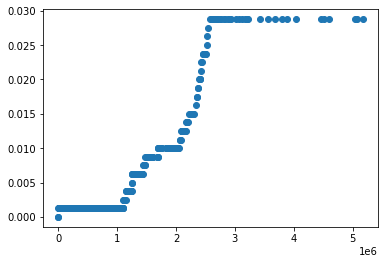

In [34]:
plt.scatter(ejection_df.columns,ejection_df.loc[ejection_df.index.unique()[0]])

In [ ]:


def find_t_stop(ejection_df, index):
    f = ejection_df.iloc[index].to_numpy()
    t = ejection_df.columns.to_numpy(dtype=float)

    peak_slope = -np.inf
    t_peak = None
    consecutive = 0

    for i in range(5, len(t)):
        # Update peak slope using a 5-point window
        slope = (f[i] - f[i-5]) / (t[i] - t[i-5])

        if slope > peak_slope:
            peak_slope = slope
            t_peak = t[i]

        # Look back 3*t_peak
        t_back = t[i] - 3*t_peak

        if f[i] < 0.07 or t_back < t[0]:
            continue

        j = np.searchsorted(t, t_back, side='right') - 1

        if f[i] - f[j] < 0.04:
            consecutive += 1
        else:
            consecutive = 0

        if consecutive >= 3:
            return t[i]

    return None



In [ ]:
t_stop = find_t_stop(ejection_df, index=1)
print(t_stop)

260699.7438350171
